# Regresión Lineal

Objetivos:
* Entender que es un modelo de regresión lineal
* Generarlo a partir de un set de entrenamiento/testeo
* Evaluar las métricas para determinar que tan bien performa/generaliza
* Analizar un ejemplo práctico y un caso real

## Presentamos un caso práctico

Recuerdan en clase 11 cuando estudiamos "correlación"?
<BR>
Habíamos generado un dataframe con alturas - pesos.
<BR>
Vamos a retomar ese ejemplo, agregando más observaciones:

In [56]:
# Importamos librerias
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [57]:
# Creamos las variables "Altura_cm" y "Peso_kg" con algunas observaciones
data = {
    "Altura_cm": [150, 155, 160, 165, 170, 175, 180, 185, 190, 195, 200, 158, 172, 178, 188],
    "Peso_kg":   [45, 50, 55, 58, 65, 70, 75, 80, 85, 90, 95, 53, 67, 72, 83]
}

# Y con ellas creamos el dataframe df
df = pd.DataFrame(data)

print("Primeros registros del Dataframe:\n", df.head())

Primeros registros del Dataframe:
    Altura_cm  Peso_kg
0        150       45
1        155       50
2        160       55
3        165       58
4        170       65


In [58]:
# Veamos algunas estadísticas
df.describe()

,Altura_cm,Peso_kg
count,15.000000,15.000000
mean,174.733333,69.533333
std,15.177364,15.263714
min,150.000000,45.000000
25%,162.500000,56.500000
50%,175.000000,70.000000
75%,186.500000,81.500000
max,200.000000,95.000000


In [59]:
# Generemos la matriz de correlacion y analizamos la relación lineal entre las variables
corr_matrix = df.corr()
corr_matrix

,Altura_cm,Peso_kg
Altura_cm,1.000000,0.999338
Peso_kg,0.999338,1.000000


El valor 0.99 indica una fuerte asociación lineal entre las variables Altura_cm y Peso_kg, lo que sugiere que un modelo de regresión lineal podría ajustarse muy bien a estos datos.
<BR>
Generemos un gráfico de dispersión (scatterplot) y otro de dispersión pero con una linea de regresión

<Axes: xlabel='Peso_kg'>

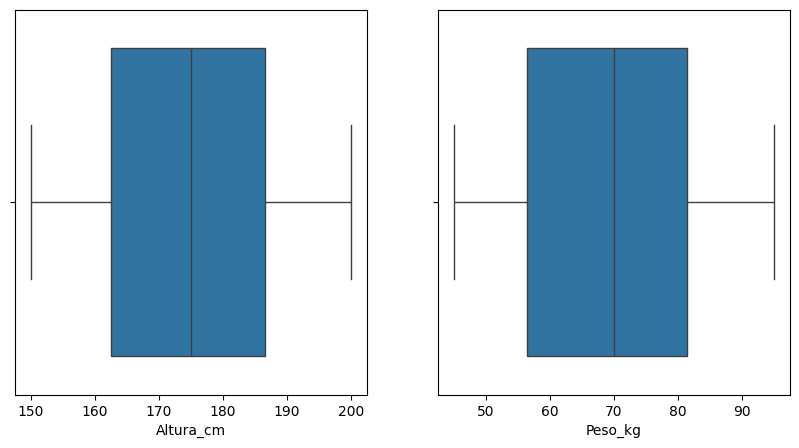

In [60]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
sns.boxplot(data=df, x="Altura_cm")

plt.subplot(1,2,2)
sns.boxplot(data=df, x="Peso_kg")

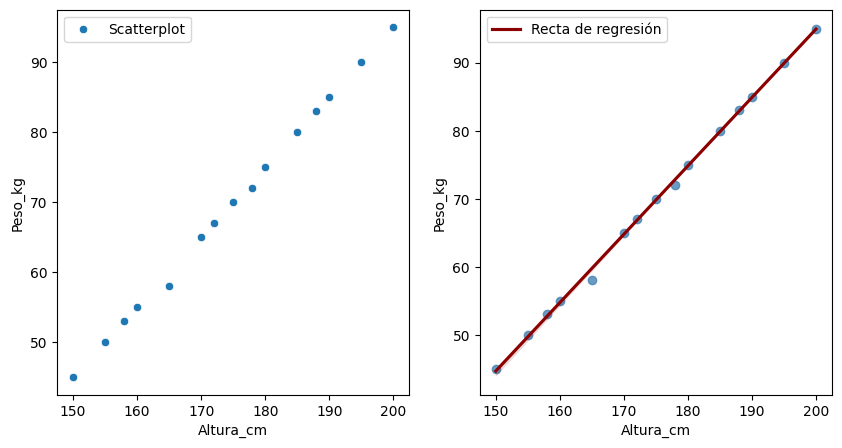

In [61]:
# Estilos y tamaños
plt.figure(figsize=(10,5))

# En el subplot izquierdo, vamos a representar un scatterplot de los datos
plt.subplot(1,2,1)
sns.scatterplot(data=df, x="Altura_cm", y="Peso_kg", label = "Scatterplot")

# En el subplot derecho, vamos a representar además una recta de regresión usnado regplot
plt.subplot(1,2,2)
sns.regplot(
    data=df,
    x="Altura_cm",
    y="Peso_kg",
    color="steelblue",
    line_kws={"color": "darkred", "label": "Recta de regresión"}
)
plt.legend()
plt.show()

## Modelo de regresión lineal simple usando sklearn

Es un modelo que predice un valor numérico usando una recta que mejor se ajusta a los datos.

Ejemplos, predecir:
* Peso por altura
* Precio por metros cuadrados
* Ventas por publicidad

El modelo busca encontrar la mejor recta posible:

y = b0 + b1*x

Donde:
* b0: es el intercepto u ordenada al orígen
* b1: es la pendiente de la recta


Para encontrar los coeficientes b0 y b1, el modelo usa el método de mínimos cuadrados, que busca que los puntos queden lo más cerca posible de la recta.

La idea es minimizar

∑(yi−y^i)2

Es decir, cuanto más pequeños sean los errores, mejor será el modelo.

Para determinar que tan bueno es el modelo, se pueden utilizar estas métricas:

* R2 (o coeficiente de determinación): cuanto más cercano a 1 mejor
* MSE (Mean Square Error): cuanto más pequeño mejor

Generamos un modelo de regresión lineal

In [62]:
# Importamos las librerías
# train_test_split para generar los conjuntos de training/testing
from sklearn.model_selection import train_test_split
# LinearRegression para generar el modelo de Regresión Lineal
from sklearn.linear_model import LinearRegression
# métricas que usaremos para evaluar el modelo
from sklearn.metrics import mean_squared_error, r2_score

Hay que particional el dataframe en dos grupos, uno de entrenamiento y otro de testing.
<BR>
Generalmente la relacion entre los conjuntos training/testing es 80/20, 75/25 o 70/30

In [63]:
# Variables independientes o predictoras X
X = df[["Altura_cm"]]

# Variable objetivo o variable respuesta y
y = df["Peso_kg"]

# Split manual - elegimos un 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [64]:
# Crear el modelo
model_rl = LinearRegression()

In [65]:
# Entrenamos el modelo a partir de los datos de training
model_rl.fit(X_train, y_train)
# Internamente calcula b0 y b1

LinearRegression()

In [66]:
# Extraemos del modelo los coeficientes b0 y b1
b1 = model_rl.coef_[0] # es el valor de la pendiente b1
b0 = model_rl.intercept_ # es el valor de la ordenada al origen b0

print(f"Modelo: Peso_kg = {b0:.2f} + {b1:.2f} * Altura_cm")

Modelo: Peso_kg = -107.26 + 1.01 * Altura_cm


In [67]:
# Usamos el modelo resultante para predecir los pesos (y_predict) a partir de las Alturas_cm del conjunto de testing (X_test)
y_pred = model_rl.predict(X_test)

In [68]:
# Métricas
# Queremos comparara los pesos de la predicción (y_predict) con los pesos del conjunto de testing (t_test)
# Calulando las métricas MSE (Mean Square Error) y R2 (Coeficiente de determinación)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("R²:", r2)
print("MSE:", mse)

R²: 0.9995497103188393
MSE: 0.1730113019393087


El valor obtenido de R2 muy cercano a 1 indica un muy buen ajuste del modelo, sumado a un valor muy pequeño de MSE. Decidimos adoptar el modelo.
<BR>
Comparemos las predicciones sobre los valores de nuestro df

In [69]:
# Creamos una tercer columna llamada "Peso_kg_pred", generada a partir de las predicciones del modelo sobre las Alturas_cm
df["Peso_kg_pred"] = model_rl.predict(X)
df

,Altura_cm,Peso_kg,Peso_kg_pred
0,150,45,44.447745
1,155,50,49.504775
2,160,55,54.561804
3,165,58,59.618833
4,170,65,64.675862
5,175,70,69.732891
6,180,75,74.789920
7,185,80,79.846950
8,190,85,84.903979
9,195,90,89.961008


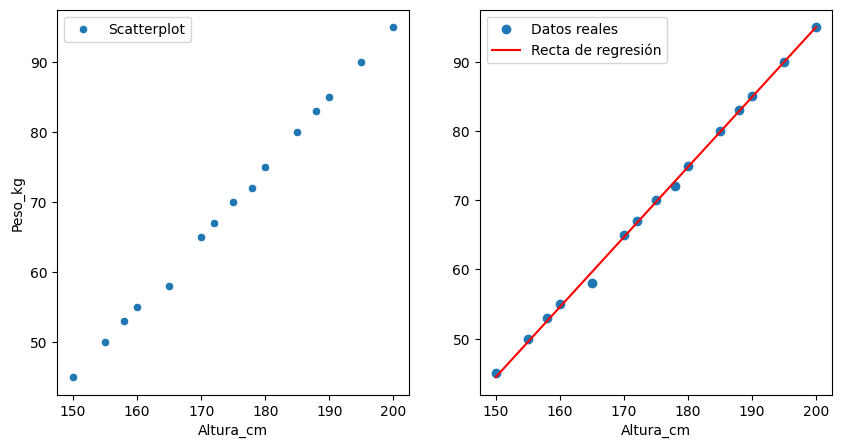

In [70]:
# Graficamos nuevamente la dispersión de alturas - pesos
# Ahora usando el modelo que generamos - recta
plt.figure(figsize=(10,5))

# En el primer subplot un scatterplot
plt.subplot(1,2,1)
sns.scatterplot(data=df, x="Altura_cm", y="Peso_kg", label="Scatterplot")

# En el segundo subplot la recta sobre el scatterplot
plt.subplot(1,2,2)
plt.scatter(X, y, label="Datos reales")
sns.lineplot(x=X["Altura_cm"], y=model_rl.predict(X), color="red", label="Recta de regresión")

plt.legend()
plt.show()


Finalmente, usemos nuestro modelo para calcular cuál es el peso de una persona a partir de su altura

In [71]:
# Dada la altura en cm 172, veamos cuál es su peso
peso = model_rl.predict([[172]])
print("El peso obtenido para una altura de 175 cm es: ", peso)

El peso obtenido para una altura de 175 cm es:  [66.69867374]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [72]:
# Dada la altura en cm 90, veamos cuál es su peso
peso = model_rl.predict([[90]])
print("El peso obtenido para una altura de 120 cm es: ", peso)

El peso obtenido para una altura de 120 cm es:  [-16.23660477]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


**Conclusión**:
<BR>
como el modelo model_lr fue entrenado con valores de Alturas_cm comprendidas entre 150 y 190 cm, no podemos garantizar la validez de las predicciones fuera de ese rango.